#

In [ ]:
---
execute:
  eval: false
  echo: true
  warning: false
format:
  html:
    code-fold: false
---

Importing the packages.

In [3]:
import torch
import deepinv as dinv
from diffusers import AutoencoderKL, UNet2DConditionModel, DDIMScheduler
from transformers import CLIPTextModel, CLIPTokenizer
import matplotlib.pyplot as plt
from PIL import Image
import requests
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Creating an inpaiting problem.

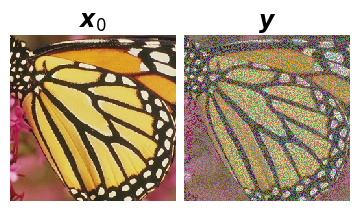

In [4]:
x = dinv.utils.load_example("butterfly.png", device=device)

transform = transforms.Compose([
    transforms.Normalize([0.5], [0.5])
])
x_true = transform(x).to(device)

keep_probability = 0.5
mask = (torch.rand((1, 3, 256, 256), device=device) < keep_probability).float()

physics = dinv.physics.Inpainting(
    img_size=(3, 256, 256),
    mask=mask,
    device=device
)

y = physics(x_true)

dinv.utils.plotting.plot([x_true, y], titles=[r"$\boldsymbol{x}_0$", r"$\boldsymbol{y}$"])

Loading a pre-trained LDM.

In [ ]:
model_id = "runwayml/stable-diffusion-v1-5"

vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae").to(device)
unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet").to(device)

tokenizer = CLIPTokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder").to(device)
empty_tokens = tokenizer([""], padding="max_length", max_length=tokenizer.model_max_length, return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    empty_embeds = text_encoder(empty_tokens)[0].detach()

Reconstructing the image using ReSample.

In [ ]:
eta = 1.0
K = 10
zeta = 10.0
resample_every = 10

data_fidelity = dinv.optim.data_fidelity.L2()

scheduler = DDIMScheduler.from_pretrained(model_id, subfolder="scheduler")
scheduler.set_timesteps(500, device=device)

alphas_cumprod = scheduler.alphas_cumprod.to(device)

z_t = torch.randn((1, unet.config.in_channels, 32, 32), device=device)

C = set(range(0, len(scheduler.timesteps) - 1, resample_every))

for i, t in enumerate(scheduler.timesteps):
    with torch.no_grad():
        noise_pred = unet(z_t, t, encoder_hidden_states=empty_embeds).sample
        alpha_bar_t = alphas_cumprod[t]
        z_hat_0 = (z_t - (1 - alpha_bar_t).sqrt() * noise_pred) / alpha_bar_t.sqrt()

        z_prev_prime = scheduler.step(noise_pred, t, z_t).prev_sample

    z_prev = z_prev_prime

    if i in C:
        z_0_y = z_hat_0.detach()

        for _ in range(K):
            z_0_y = z_0_y.detach().requires_grad_(True)
            x_hat_0 = vae.decode(z_0_y / vae.config.scaling_factor).sample

            loss_meas = data_fidelity(x_hat_0, y, physics)
            grad_meas = torch.autograd.grad(loss_meas, z_0_y)[0]

            with torch.no_grad():
                z_0_y = z_0_y - eta * grad_meas

        if i + 1 < len(scheduler.timesteps):
            t_prev = scheduler.timesteps[i + 1]
            alpha_bar_prev = alphas_cumprod[t_prev]

            if t_prev.item() > 0:
                alpha_bar_prevprev = alphas_cumprod[t_prev - 1]

                sigma2 = (zeta * (1 - alpha_bar_prev) / alpha_bar_prev * (1 - alpha_bar_prev / alpha_bar_prevprev))
            else:
                sigma2 = torch.zeros_like(alpha_bar_prev)

            denom = sigma2 + (1 - alpha_bar_prev)

            mu = (sigma2 * alpha_bar_prev.sqrt() * z_0_y + (1 - alpha_bar_prev) * z_prev_prime) / denom.clamp_min(1e-12)
            var = (sigma2 * (1 - alpha_bar_prev) / denom.clamp_min(1e-12))

            with torch.no_grad():
                z_prev = mu + var.clamp_min(0).sqrt() * torch.randn_like(z_prev_prime)

    z_t = z_prev.detach()

with torch.no_grad():
    x_recon = vae.decode(z_t / vae.config.scaling_factor).sample

Plotting the results.

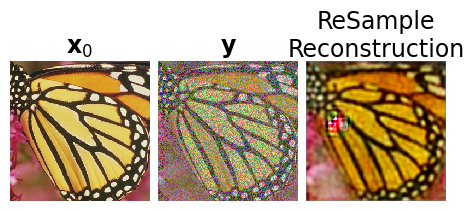

In [28]:
imgs = [x_true, y, x_recon.clip(-1.0, 1.0)]
titles = [r"$\mathbf{x}_0$", r"$\mathbf{y}$", r"ReSample Reconstruction"]

dinv.utils.plotting.plot(imgs, titles=titles, cmap="gray")